In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../data/Algerian_forest_fires_Cleaned_dataset.csv')
df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0,0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,0,0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,0,0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,0,0
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,0,0


In [3]:
df.drop(["day", "month", "year"], axis=1, inplace=True)

In [4]:
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,0,0


In [5]:
X = df.drop("FWI", axis=1)
y = df["FWI"]

In [6]:
X.shape,y.shape

((243, 11), (243,))

In [7]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=42)

In [8]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((182, 11), (61, 11), (182,), (61,))

#### Takes your dataset
#### Calculates correlation between all columns
#### Uses a threshold, for example 0.8
#### Checks which correlations are stronger than 0.8
#### Collects the names of those highly correlated columns
#### Returns those column names

In [9]:
def correlation(dataset, threshold):
    col_corr = set()
    corr_matrix = dataset.corr()

    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold:
                colname = corr_matrix.columns[i]
                col_corr.add(colname)

    return col_corr

In [10]:
corr_features = correlation(X_train, 0.85)

print(corr_features)

{'BUI', 'DC'}


In [11]:
X_train = X_train.drop(corr_features, axis=1)
X_test = X_test.drop(corr_features, axis=1)

In [12]:
X_train.shape, X_test.shape

((182, 9), (61, 9))

In [13]:
X_train = X_train.drop("Classes", axis=1)
X_test = X_test.drop("Classes", axis=1)

X_train.shape, X_test.shape

((182, 8), (61, 8))

## Feature Scaling/Standardization

In [14]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [15]:
X_train_scaled

array([[-0.84284248,  0.78307967,  1.29972026, ..., -0.88272888,
        -0.62963326, -0.98907071],
       [-0.30175842,  0.64950844, -0.59874754, ..., -0.86687565,
        -0.93058524,  1.01105006],
       [ 2.13311985, -2.08870172, -0.21905398, ...,  0.61540157,
         2.7271388 ,  1.01105006],
       ...,
       [-1.9250106 ,  0.9166509 ,  0.54033314, ..., -1.06504105,
        -1.06948615, -0.98907071],
       [ 0.50986767, -0.21870454,  0.16063958, ...,  0.37760309,
         0.5973248 ,  1.01105006],
       [-0.57230045,  0.98343651,  2.05910739, ..., -1.01748135,
        -0.86113478, -0.98907071]])

## Box Plots To understand Effect Of Standard Scaler

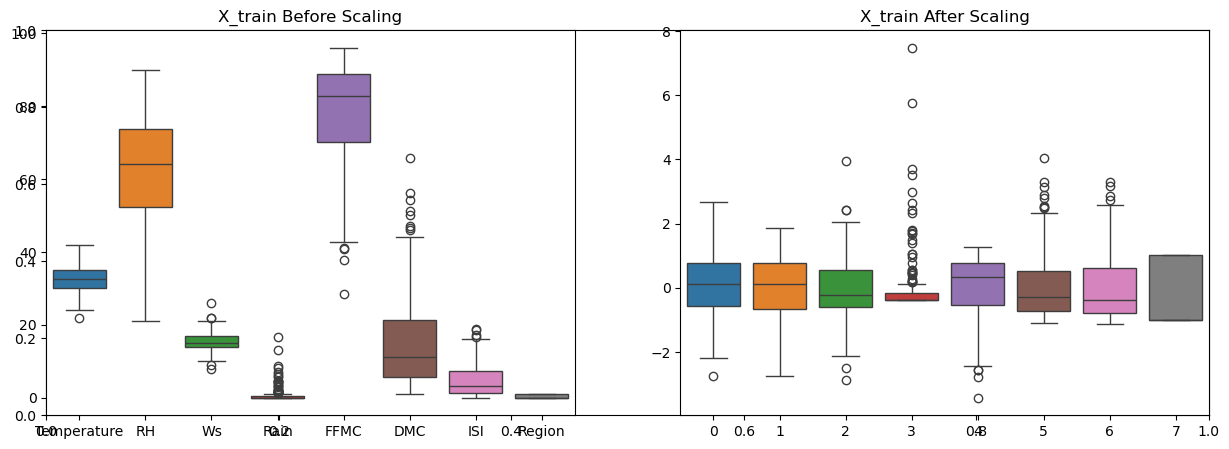

In [16]:
plt.subplots(figsize=(15,5))
plt.subplot(1,2,1)
sns.boxplot(data=X_train)
plt.title('X_train Before Scaling')
plt.subplot(1,2,2)
sns.boxplot(data=X_train_scaled)
plt.title('X_train After Scaling')
plt.show()


## Linear Regression Model

Mean Absolute Error 0.5806361642310044
R2 Score 0.9830321384727897


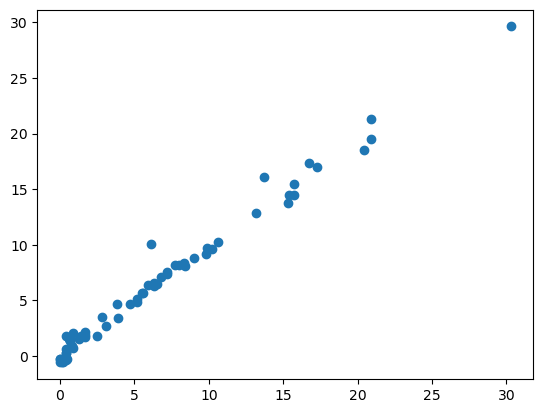

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

linreg=LinearRegression()
linreg.fit(X_train_scaled,y_train)
y_pred=linreg.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)

print("Mean Absolute Error",mae)
print("R2 Score",score)

plt.scatter(y_test,y_pred)
plt.show()

## Lasso Regression Model

Mean Absolute Error 1.1331759949144087
R2 Score 0.9492020263112388


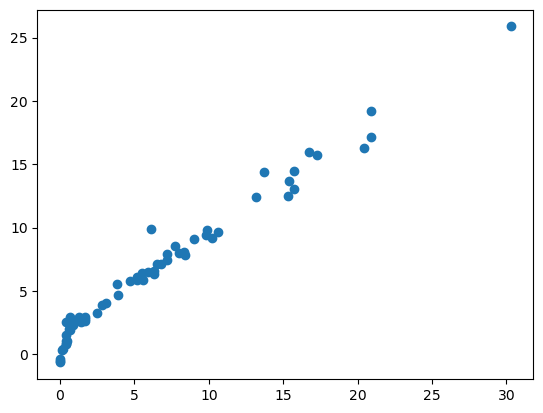

In [18]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

lasso=Lasso()
lasso.fit(X_train_scaled,y_train)
y_pred=lasso.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)

print("Mean Absolute Error",mae)
print("R2 Score",score)

plt.scatter(y_test,y_pred)
plt.show()

## Cross Validation Lasso

In [19]:
from sklearn.linear_model import LassoCV
lassocv = LassoCV(cv = 5)
lassocv.fit(X_train_scaled,y_train)

LassoCV(cv=5)

In [20]:
lassocv.predict(X_test_scaled)

array([ 8.08952031,  7.60634427, -0.23265137,  4.85376352,  6.64303299,
        1.85071189,  2.02905324,  7.50884393,  2.09918879,  3.54499811,
        0.71690527, 10.12577585,  9.27314139, 16.9852939 , 18.32770763,
        1.7118691 ,  1.65149733, -0.69890609,  7.18680807,  2.9168583 ,
        2.10112926,  0.22272815,  6.38582103,  0.18730216, 21.10321595,
        4.95691637,  5.73407458,  9.68896291, -0.84854545,  9.84270612,
        6.60390084, -0.28762084, 10.25249099, 14.41195231,  1.85133635,
        0.92040677,  1.85163023,  5.80915143, -0.67293229, -0.61138016,
        6.33872968,  2.2310956 ,  8.38514557, -0.90109748, 15.41278412,
        8.24248499,  8.3558967 ,  1.51809838, 12.98085178,  1.29519655,
       29.22354342,  5.33793198, 17.20273664, 19.3296297 , 13.7202024 ,
       16.01521006,  1.06760138,  8.99046251,  3.66660586, 14.41813208,
        5.07383409])

In [21]:
lassocv.alpha_ #Alpha value selected

np.float64(0.049796533886308954)

In [22]:
lassocv.alphas_ #All alpha values tried on

array([7.05853002, 6.58280872, 6.13914944, 5.72539132, 5.33951911,
       4.97965339, 4.64404142, 4.33104857, 4.03915039, 3.76692517,
       3.51304702, 3.27627941, 3.05546914, 2.84954075, 2.65749124,
       2.47838523, 2.31135036, 2.15557308, 2.01029467, 1.87480753,
       1.74845178, 1.63061198, 1.52071419, 1.41822315, 1.32263965,
       1.23349817, 1.15036452, 1.0728338 , 1.00052839, 0.93309613,
       0.87020857, 0.81155943, 0.75686304, 0.705853  , 0.65828087,
       0.61391494, 0.57253913, 0.53395191, 0.49796534, 0.46440414,
       0.43310486, 0.40391504, 0.37669252, 0.3513047 , 0.32762794,
       0.30554691, 0.28495408, 0.26574912, 0.24783852, 0.23113504,
       0.21555731, 0.20102947, 0.18748075, 0.17484518, 0.1630612 ,
       0.15207142, 0.14182231, 0.13226397, 0.12334982, 0.11503645,
       0.10728338, 0.10005284, 0.09330961, 0.08702086, 0.08115594,
       0.0756863 , 0.0705853 , 0.06582809, 0.06139149, 0.05725391,
       0.05339519, 0.04979653, 0.04644041, 0.04331049, 0.04039

In [23]:
lassocv.mse_path_ #100 alphas * 5 fold = 500 mse's

array([[53.64536329, 65.39074075, 54.89628985, 77.90299066, 39.38236846],
       [46.99139716, 59.81506814, 49.29840831, 75.6645852 , 35.31758355],
       [41.14908917, 53.9178721 , 42.49594889, 68.35708298, 31.76996123],
       [36.05788169, 48.41773965, 36.66879347, 61.92819453, 28.67296816],
       [31.62067285, 42.76466229, 31.68391904, 56.26841266, 24.93183295],
       [27.75285367, 37.81922812, 27.42599138, 51.28216115, 21.56888645],
       [24.3807738 , 33.49107651, 23.7950306 , 45.25481907, 18.66094162],
       [21.44052804, 29.70161639, 20.70460191, 39.90418045, 16.14837778],
       [18.876308  , 26.38208059, 18.07969934, 35.23429953, 13.97821475],
       [16.63960395, 23.47341883, 15.85530749, 31.15712074, 12.10483403],
       [14.68819307, 20.92329068, 13.97555108, 27.59649208, 10.48862803],
       [12.98525144, 18.68636627, 12.39173305, 24.48611006,  9.09521221],
       [11.49893734, 16.72312788, 11.06186319, 21.7677198 ,  7.89445038],
       [10.2013182 , 14.9991189 ,  9.9

Mean Absolute Error 0.6297839301098622
R2 Score 0.981393944688068


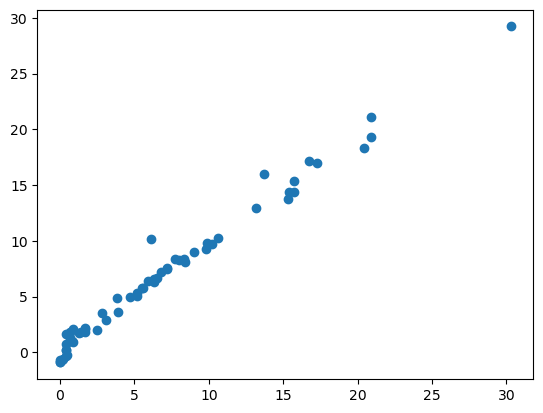

In [24]:
y_pred=lassocv.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)

print("Mean Absolute Error",mae)
print("R2 Score",score)

plt.scatter(y_test,y_pred)
plt.show()

## Ridge Regression Model

Mean Absolute Error 0.5969613029130073
R2 Score 0.9824907652592586


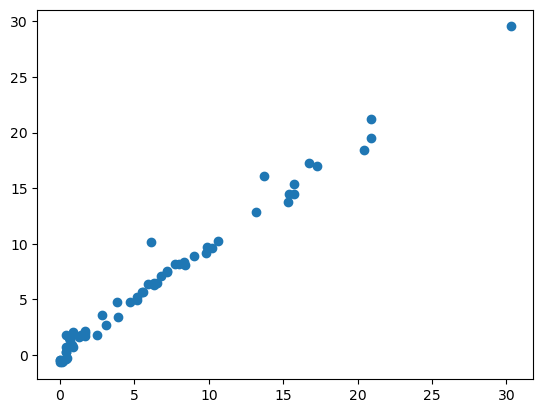

In [25]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

ridge=Ridge()
ridge.fit(X_train_scaled,y_train)
y_pred=ridge.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)

print("Mean Absolute Error",mae)
print("R2 Score",score)

plt.scatter(y_test,y_pred)
plt.show()

## Cross Validation Ridge

Mean Absolute Error 0.5969613029130073
R2 Score 0.9824907652592586


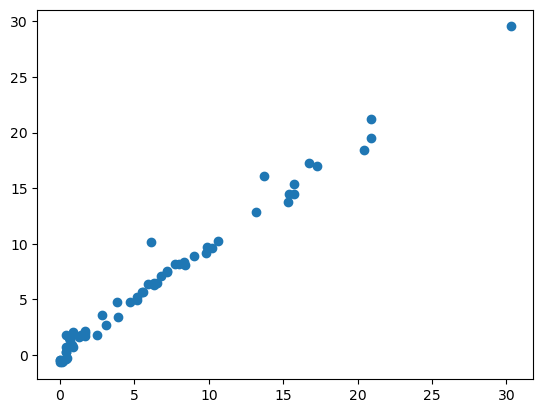

In [26]:
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

ridgecv=RidgeCV(cv = 5)
ridgecv.fit(X_train_scaled,y_train)
y_pred=ridgecv.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)

print("Mean Absolute Error",mae)
print("R2 Score",score)

plt.scatter(y_test,y_pred)
plt.show()

In [27]:
ridgecv.alpha_ #Alpha Selected

np.float64(1.0)

In [28]:
ridgecv.alphas #Different Alphas

(0.1, 1.0, 10.0)

In [29]:
ridgecv.get_params()

{'alpha_per_target': False,
 'alphas': (0.1, 1.0, 10.0),
 'cv': 5,
 'fit_intercept': True,
 'gcv_mode': None,
 'scoring': None,
 'store_cv_results': None,
 'store_cv_values': 'deprecated'}

## ElasticNet Regression Model

Mean Absolute Error 1.9284414511796724
R2 Score 0.868664603256521


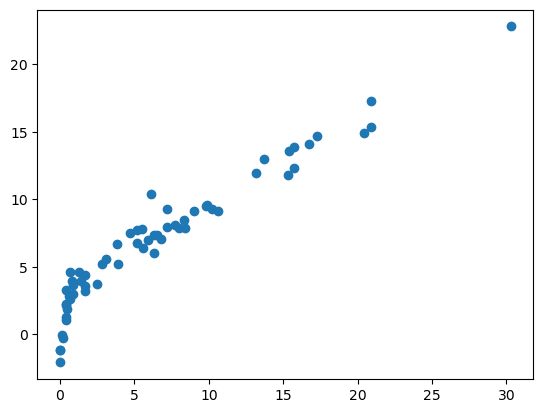

In [30]:
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

elastic=ElasticNet()
elastic.fit(X_train_scaled,y_train)
y_pred=elastic.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)

print("Mean Absolute Error",mae)
print("R2 Score",score)

plt.scatter(y_test,y_pred)
plt.show()

## Cross Validation ElasticNet 

Mean Absolute Error 0.6716732201553719
R2 Score 0.9796396289421408


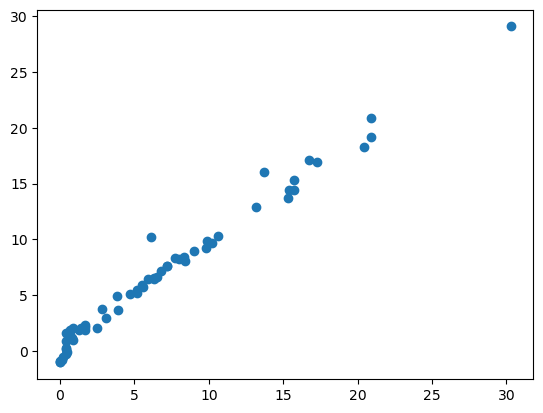

In [31]:
from sklearn.linear_model import ElasticNetCV
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

elasticcv=ElasticNetCV(cv=5)
elasticcv.fit(X_train_scaled,y_train)
y_pred=elasticcv.predict(X_test_scaled)

mae = mean_absolute_error(y_test,y_pred)
score = r2_score(y_test,y_pred)

print("Mean Absolute Error",mae)
print("R2 Score",score)

plt.scatter(y_test,y_pred)
plt.show()

## Model Comparison

The following table compares the performance of all trained regression models using Mean Absolute Error (MAE) and R² Score.

In [32]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Lasso",
        "LassoCV",
        "Ridge",
        "RidgeCV",
        "ElasticNet",
        "ElasticNetCV"
    ],
    "MAE": [
        0.5806,
        1.1332,
        0.6298,
        0.5970,
        0.5970,
        1.9284,
        0.6717
    ],
    "R2 Score": [
        0.9830,
        0.9492,
        0.9814,
        0.9825,
        0.9825,
        0.8687,
        0.9764
    ]
})

results

,Model,MAE,R2 Score
0,Linear Regression,0.5806,0.9830
1,Lasso,1.1332,0.9492
2,LassoCV,0.6298,0.9814
3,Ridge,0.5970,0.9825
4,RidgeCV,0.5970,0.9825
5,ElasticNet,1.9284,0.8687
6,ElasticNetCV,0.6717,0.9764


In [33]:
print("Best Alpha:", ridgecv.alpha_)

Best Alpha: 1.0


In [34]:
print("Linear Regression Coefficients:")
print(linreg.coef_)

Linear Regression Coefficients:
[-4.35017430e-02 -4.73416948e-02 -1.37685898e-02 -2.24525639e-03
 -5.66266728e-01  3.71596688e+00  5.04512318e+00 -3.94672738e-01]


## Pickle the machine learning models, preprocessing model standarscaler

In [35]:
import pickle

pickle.dump(linreg, open("../models/linear_regression.pkl", "wb"))
pickle.dump(scaler, open("../models/scaler.pkl", "wb"))

print("Model and scaler saved successfully!")

Model and scaler saved successfully!
